# 4 · Comparison with the eddy-covariance flux

## Skill metrics

Most measured fluxes lie within a few W m⁻² of zero (Chapter 1), so an estimate close to zero everywhere has a small
error without containing information. The table therefore includes the trivial estimate $H = 0$ on every segment; its
mean absolute error (MAE) and RMSE can be compared with those of the actual estimates.

The paper uses two separate measures:

* **slope $b$** of the regression of the estimate on the EC flux: the fraction of the observed *amplitude* recovered (ideal: 1);
* **correlation $r$**: agreement of estimate and reference in their variability (ideal: 1).

The slope equals $r$ times the ratio of the standard deviations of estimate and reference. A slope near 1 can therefore
result from the correct amplitude with good correlation or from excess variance with poor correlation; $b$ and $r$ are
interpreted together.

> [!NOTE]
> **Paper:** Sect. 4.1, Table 4, Figs. 4–6. **Code:** `fluxpy/sensitivity.py` (`skill_metrics`),
> `scripts/manuscript_numbers.py` (every number of Sect. 4.1), `figures_manuscript/fig06_flux_scatter.py`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path("..").resolve(); sys.path.insert(0, str(REPO))
plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

AR  = REPO / "data/observations/ar"
FIG = xr.open_dataset(REPO / "data/model_output/sensitivity_figure_data.nc")      # all flux estimates, 90 segments
SEG = xr.open_dataset(AR / "analysis_ready_polar6_turbulent_fluxes_latest_5km.nc").sel(start_time=FIG.start_time.values)
EC  = FIG["H_obs_ec"].values

from fluxpy.sensitivity import skill_metrics
import logging; logging.disable(logging.INFO)
NAMES = {"H_obs_bulk": "H_S,obs,bulk  (measured inputs)", "H_rs_bulk": "H_S,RS,bulk   (MODIS + ERA5)",
         "H_era_bulk": "H_S,ERA,bulk  (ERA5 only)", "H_era_diag": "H_S,ERA,diag  (ERA5's own flux)", "H_car_diag": "H_S,CAR,diag  (CARRA's own flux)"}
T = pd.to_datetime(FIG.start_time.values)
LEG = np.cumsum(np.r_[0, np.diff(T.values) / np.timedelta64(1, "m")] > 10)          # a new leg after a gap of > 10 min

def r_leg(h):
    """correlation after removing the mean of every leg: only the variability along the legs counts"""
    d = pd.DataFrame({"ec": EC, "h": h, "leg": LEG}).dropna()
    a = d.groupby("leg")[["ec", "h"]].transform(lambda s: s - s.mean())
    return np.corrcoef(a.ec, a.h)[0, 1]

rows = {}
for key, name in NAMES.items():
    h = FIG[key].values; ok = np.isfinite(h)
    m = skill_metrics(EC, h, key)
    rows[name] = {"slope b": m["slope"], "r": m["r"], "r_leg": r_leg(h), "sd ratio": m["std_ratio"], "bias (W m-2)": m["bias"],
                  "MAE (W m-2)": np.mean(np.abs(h[ok] - EC[ok])), "RMSE (W m-2)": m["rmse"], "n": m["n"]}
rows["zero flux  (H = 0 everywhere)"] = {"bias (W m-2)": -EC.mean(), "MAE (W m-2)": np.mean(np.abs(EC)),
                                        "RMSE (W m-2)": np.sqrt(np.mean(EC ** 2)), "n": EC.size}
table = pd.DataFrame(rows).T.round(1); table["n"] = table["n"].astype(int)
table.fillna("–")

,slope b,r,r_leg,sd ratio,bias (W m-2),MAE (W m-2),RMSE (W m-2),n
"H_S,obs,bulk (measured inputs)",1.6,0.7,0.5,2.3,1.2,3.9,6.1,90
"H_S,RS,bulk (MODIS + ERA5)",0.8,0.5,0.1,1.5,-2.3,4.0,5.3,90
"H_S,ERA,bulk (ERA5 only)",0.3,0.4,-0.1,0.9,-4.1,4.2,5.7,90
"H_S,ERA,diag (ERA5's own flux)",1.2,0.6,-0.1,2.1,-2.8,4.7,6.8,90
"H_S,CAR,diag (CARRA's own flux)",1.2,0.6,0.3,2.1,-3.6,4.9,7.5,73
zero flux (H = 0 everywhere),–,–,–,–,-2.1,2.7,4.1,90


(CARRA is not available on 13 April, hence the smaller *n*.) The zero estimate has a smaller MAE and RMSE than every
estimate in the table: in this weak-flux regime, these error measures reward conservative estimates, not skill.

$r_\mathrm{leg}$ is the correlation after removing the mean of each leg from both series (Table 4 of the paper). It
measures whether an estimate follows the flux from segment to segment *along* a leg, rather than only the differences
between flight days. Only the estimate with measured inputs does so clearly.

The model-diagnosed fluxes of ERA5 and CARRA overestimate the amplitude (slope above 1) and are biased low. They follow
the observed variability better than the offline ERA5-only estimate, which the paper attributes to their internal skin
temperature and much larger scalar roughness (Sect. 2.2 and Discussion), but follow it only weakly along the legs.

## Bulk estimates against the reference (Fig. 6)

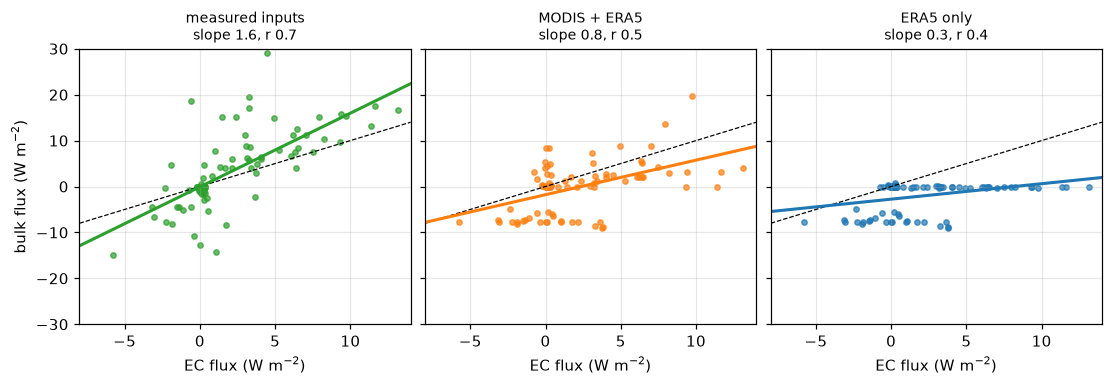

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4), sharex=True, sharey=True)
for ax, key, c in zip(axs, ["H_obs_bulk", "H_rs_bulk", "H_era_bulk"], ["C2", "C1", "C0"]):
    h = FIG[key].values; ok = np.isfinite(EC) & np.isfinite(h); b, a = np.polyfit(EC[ok], h[ok], 1)
    ax.scatter(EC[ok], h[ok], s=12, color=c, alpha=0.7); xx = np.array([-8, 14])
    ax.plot(xx, xx, "k--", lw=0.8); ax.plot(xx, a + b * xx, color=c, lw=2)
    ax.set_title(f"{NAMES[key].split('(')[1][:-1]}\nslope {b:.1f}, r {np.corrcoef(EC[ok], h[ok])[0, 1]:.1f}", fontsize=9)
    ax.set_xlabel("EC flux (W m$^{-2}$)"); ax.set_xlim(-8, 14); ax.set_ylim(-30, 30)
axs[0].set_ylabel("bulk flux (W m$^{-2}$)");

From left to right, the panels show the main result of the paper (numbers in the panel titles):

* **Measured inputs:** the highest correlation, but the amplitude is overestimated (slope well above 1). With measured
  inputs, the conventional transfer coefficient is too large (Chapter 5).
* **MODIS surface temperature:** with the ERA5 atmosphere unchanged, amplitude and correlation both increase.
* **ERA5 only:** the regression line is nearly flat; a small part of the amplitude is recovered and the correlation is weak.

## Effect of the satellite surface temperature

If the benefit of MODIS arises from resolving leads and thin ice that ERA5 does not represent, it should be greatest for
segments with a *heterogeneous* surface. The segments are split at the median of the within-segment standard deviation
of the KT-19 surface temperature.

In [3]:
sd = SEG.T_sfc_std.values; rs, era = FIG.H_rs_bulk.values, FIG.H_era_bulk.values
ok = np.isfinite(EC) & np.isfinite(rs) & np.isfinite(era) & np.isfinite(sd); med = np.median(sd[ok])
rows = {}
for label, m in (("heterogeneous half", ok & (sd > med)), ("homogeneous half", ok & (sd <= med))):
    rows[label] = {"n": int(m.sum()), "r  ERA5 only": np.corrcoef(EC[m], era[m])[0, 1], "r  with MODIS": np.corrcoef(EC[m], rs[m])[0, 1],
                   "slope  ERA5 only": np.polyfit(EC[m], era[m], 1)[0], "slope  with MODIS": np.polyfit(EC[m], rs[m], 1)[0]}
print(f"median within-segment standard deviation of the surface temperature: {med:.1f} K"); pd.DataFrame(rows).T.round(1)

median within-segment standard deviation of the surface temperature: 1.2 K


,n,r ERA5 only,r with MODIS,slope ERA5 only,slope with MODIS
heterogeneous half,45.0,-0.4,0.4,-0.0,0.5
homogeneous half,45.0,0.3,0.4,0.4,0.6


**Summary.** The surface temperature determines whether a bulk estimate follows the observed variability. The ERA5
surface temperature does not represent leads and thin ice within a grid cell; on heterogeneous segments the ERA5-only
flux is anti-correlated with the measurement, and replacing the surface temperature by MODIS has the largest effect there.